# Notebook 2 — Préparation des données et modélisation

## Objectif

Ce notebook poursuit l'analyse exploratoire réalisée dans le notebook 1 en préparant les données UNSW-NB15 pour la détection de comportements atypiques.

L'objectif est de construire et de comparer plusieurs configurations de K-Means, d'évaluer leurs performances sur le jeu de test et d'étudier les compromis entre détection des attaques et fausses alertes.

Les résultats obtenus serviront de base à l'analyse économique et à la décision métier présentées dans le notebook 3.

---


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (8, 4)

Importation de NumPy et pandas pour les calculs et tableaux, Matplotlib pour les figures et scikit-learn pour le prétraitement, le clustering et les métriques. `random_state=42` dans les modèles ultérieurs contribue à la reproductibilité.

---

In [2]:
df_train = pd.read_csv("UNSW_NB15_training-set.csv")
df_test = pd.read_csv("UNSW_NB15_testing-set.csv")

print("Dimensions du Train :", df_train.shape)
print("Dimensions du Test :", df_test.shape)

Dimensions du Train : (82332, 45)
Dimensions du Test : (175341, 45)


Lecture des deux fichiers UNSW-NB15 fournis. Le fichier d’apprentissage comporte **82 332 lignes et 45 colonnes**, celui de test **175 341 lignes et 45 colonnes**. Le test reste distinct de l’apprentissage.


---

In [3]:
colonnes_exclues = ["id", "label", "attack_cat"]

X_train = df_train.drop(columns=colonnes_exclues)
X_test = df_test.drop(columns=colonnes_exclues)

y_train = df_train[["label", "attack_cat"]].copy()
y_test = df_test[["label", "attack_cat"]].copy()

print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test :", X_test.shape)

print("Dimensions de y_train :", y_train.shape)
print("Dimensions de y_test :", y_test.shape)

print("Colonnes identiques :", X_train.columns.equals(X_test.columns))

Dimensions de X_train : (82332, 42)
Dimensions de X_test : (175341, 42)
Dimensions de y_train : (82332, 2)
Dimensions de y_test : (175341, 2)
Colonnes identiques : True


`X_train` et `X_test` contiennent les **42 variables descriptives**. `id` est un identifiant, tandis que `label` et `attack_cat` sont réservées à l’évaluation et à l’interprétation. Cette exclusion évite que les véritables réponses soient fournies au clustering. Les étiquettes sont conservées dans `y_train` et `y_test`.

---

In [4]:
colonnes_numeriques = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

colonnes_categorielles = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Nombre de variables numériques :", len(colonnes_numeriques))
print("Nombre de variables catégorielles :", len(colonnes_categorielles))

print("\nVariables catégorielles :")
print(colonnes_categorielles)

print("\nTotal des variables :", 
      len(colonnes_numeriques) + len(colonnes_categorielles))

Nombre de variables numériques : 39
Nombre de variables catégorielles : 3

Variables catégorielles :
['proto', 'service', 'state']

Total des variables : 42


Identification de **39 variables numériques** et **3 catégorielles** (`proto`, `service`, `state`). Les premières seront mises à l’échelle, les secondes seront encodées pour pouvoir être exploitées par K-Means.

---

In [5]:
pipeline_numerique = Pipeline([
    ("standardisation", StandardScaler())
])

pipeline_categoriel = Pipeline([
    ("encodage", OneHotEncoder(handle_unknown="ignore"))
])

preprocesseur = ColumnTransformer([
    ("numerique", pipeline_numerique, colonnes_numeriques),
    ("categoriel", pipeline_categoriel, colonnes_categorielles)
])

print("Pipeline de prétraitement créé.")
print(preprocesseur)

Pipeline de prétraitement créé.
ColumnTransformer(transformers=[('numerique',
                                 Pipeline(steps=[('standardisation',
                                                  StandardScaler())]),
                                 ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes',
                                  'rate', 'sttl', 'dttl', 'sload', 'dload',
                                  'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit',
                                  'djit', 'swin', 'stcpb', 'dtcpb', 'dwin',
                                  'tcprtt', 'synack', 'ackdat', 'smean',
                                  'dmean', 'trans_depth', 'response_body_len',
                                  'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', ...]),
                                ('categoriel',
                                 Pipeline(steps=[('encodage',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                

`StandardScaler` standardise les variables numériques : $z=(x-\mu_{train})/\sigma_{train}$. `OneHotEncoder` crée une colonne indicatrice par modalité catégorielle, `handle_unknown="ignore"` évite une erreur lorsqu’une modalité inconnue apparaît au test. `ColumnTransformer` combine ces opérations.

---

In [6]:
X_train_prepare = preprocesseur.fit_transform(X_train)

print("Type des données préparées :", type(X_train_prepare))
print("Dimensions initiales :", X_train.shape)
print("Dimensions après prétraitement :", X_train_prepare.shape)

print(
    "Nombre de caractéristiques après prétraitement :",
    len(preprocesseur.get_feature_names_out())
)

print(
    "Valeurs manquantes ou infinies :",
    not np.isfinite(X_train_prepare.data).all()
)

Type des données préparées : <class 'scipy.sparse._csr.csr_matrix'>
Dimensions initiales : (82332, 42)
Dimensions après prétraitement : (82332, 190)
Nombre de caractéristiques après prétraitement : 190
Valeurs manquantes ou infinies : False


`fit_transform(X_train)` calcule les paramètres **uniquement sur le Train**, puis transforme ses observations. Les 42 variables deviennent **190 caractéristiques encodées**. Le résultat est une matrice creuse CSR, la vérification des valeurs stockées ne signale ni NaN ni infini.


---

In [7]:
X_test_prepare = preprocesseur.transform(X_test)

print("Dimensions de X_train préparé :", X_train_prepare.shape)
print("Dimensions de X_test préparé :", X_test_prepare.shape)

print(
    "Valeurs manquantes ou infinies dans le Test :",
    not np.isfinite(X_test_prepare.data).all()
)

print(
    "Même nombre de caractéristiques :",
    X_train_prepare.shape[1] == X_test_prepare.shape[1]
)

Dimensions de X_train préparé : (82332, 190)
Dimensions de X_test préparé : (175341, 190)
Valeurs manquantes ou infinies dans le Test : False
Même nombre de caractéristiques : True


`transform(X_test)` réutilise les paramètres appris sur le Train sans les recalculer : **175 341 × 190**. Cette séparation empêche une fuite d’information provenant du Test.

---

In [8]:
variables_a_examiner = ["dur", "spkts", "sbytes", "rate"]

scaler = preprocesseur.named_transformers_["numerique"].named_steps["standardisation"]

indices = [colonnes_numeriques.index(col) for col in variables_a_examiner]

valeurs_standardisees = pd.DataFrame(
    X_train_prepare[:, indices].toarray(),
    columns=variables_a_examiner
)

print(valeurs_standardisees.describe().round(2))

            dur     spkts    sbytes      rate
count  82332.00  82332.00  82332.00  82332.00
mean      -0.00      0.00     -0.00      0.00
std        1.00      1.00      1.00      1.00
min       -0.21     -0.13     -0.05     -0.55
25%       -0.21     -0.12     -0.05     -0.55
50%       -0.21     -0.09     -0.04     -0.54
75%       -0.06     -0.05     -0.04      0.19
max       12.52     79.36     83.59      6.17


Sur `dur`, `spkts`, `sbytes` et `rate`, les moyennes standardisées sont proches de 0 et les écarts-types de 1. Les maxima restent très élevés : standardiser ne supprime pas l’asymétrie ni les valeurs extrêmes.

---

Statistiques après transformation logarithmique :
            dur     spkts    sbytes      rate
count  82332.00  82332.00  82332.00  82332.00
mean       0.33      2.04      6.31      7.50
std        0.57      1.08      1.61      4.13
min        0.00      0.69      3.22      0.00
25%        0.00      1.10      4.74      3.39
50%        0.01      1.95      6.28      7.88
75%        0.54      2.56      7.16     11.62
max        4.11      9.27     16.48     13.82


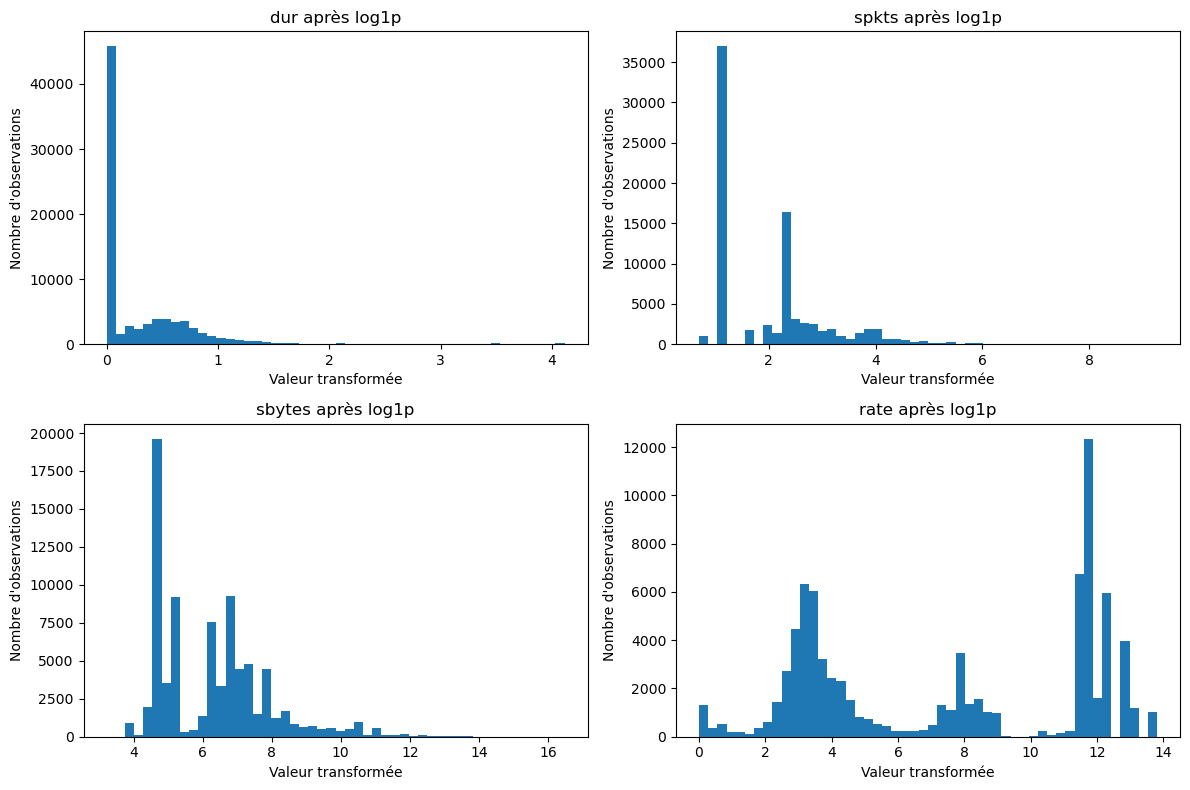

In [9]:
variables_a_examiner = ["dur", "spkts", "sbytes", "rate"]

valeurs_originales = X_train[variables_a_examiner]

valeurs_log = np.log1p(valeurs_originales)

print("Statistiques après transformation logarithmique :")
print(valeurs_log.describe().round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, colonne in zip(axes.flat, variables_a_examiner):
    ax.hist(valeurs_log[colonne], bins=50)
    ax.set_title(f"{colonne} après log1p")
    ax.set_xlabel("Valeur transformée")
    ax.set_ylabel("Nombre d'observations")

plt.tight_layout()
plt.show()

`log1p(x)=ln(1+x)` comprime les grandes valeurs tout en acceptant zéro. Les histogrammes permettent d’observer la distribution de quatre variables fortement asymétriques. Ici, la transformation est **exploratoire** et ne modifie pas encore le pipeline A.

---

In [10]:
minimums = X_train[colonnes_numeriques].min()

variables_negatives = minimums[minimums < 0]
variables_non_negatives = minimums[minimums >= 0]

print("Nombre de variables numériques :", len(colonnes_numeriques))
print("Variables contenant des valeurs négatives :", len(variables_negatives))
print("Variables uniquement non négatives :", len(variables_non_negatives))

print("\nVariables avec valeurs négatives :")
print(variables_negatives)

print("\nMinimums des quatre variables examinées :")
print(minimums[["dur", "spkts", "sbytes", "rate"]])

Nombre de variables numériques : 39
Variables contenant des valeurs négatives : 0
Variables uniquement non négatives : 39

Variables avec valeurs négatives :
Series([], dtype: float64)

Minimums des quatre variables examinées :
dur        0.0
spkts      1.0
sbytes    24.0
rate       0.0
dtype: float64


Le minimum de chaque variable numérique est contrôlé avant transformation. `log1p` est directement adapté aux variables non négatives retenues, les quatre variables étudiées ont bien des minimums positifs ou nuls. Il ne faut pas appliquer automatiquement ce traitement à une variable négative.

---

In [11]:
colonnes_log = ["dur", "spkts", "sbytes", "rate"]

colonnes_numeriques_restantes = [
    col for col in colonnes_numeriques
    if col not in colonnes_log
]

pipeline_log = Pipeline([
    ("logarithme", FunctionTransformer(np.log1p)),
    ("standardisation", StandardScaler())
])

pipeline_numerique_simple = Pipeline([
    ("standardisation", StandardScaler())
])

preprocesseur_B = ColumnTransformer([
    ("numerique_log", pipeline_log, colonnes_log),
    ("numerique_simple", pipeline_numerique_simple, colonnes_numeriques_restantes),
    ("categoriel", OneHotEncoder(handle_unknown="ignore"), colonnes_categorielles)
])

print("Pipeline B créé.")
print("Variables avec log1p :", colonnes_log)
print("Autres variables numériques :", len(colonnes_numeriques_restantes))
print("Variables catégorielles :", len(colonnes_categorielles))

Pipeline B créé.
Variables avec log1p : ['dur', 'spkts', 'sbytes', 'rate']
Autres variables numériques : 35
Variables catégorielles : 3


Les quatre variables `dur`, `spkts`, `sbytes`, `rate` reçoivent `log1p`, puis `StandardScaler`. Les **35 autres variables numériques** sont standardisées sans logarithme, les trois variables catégorielles sont encodées. L’objectif est de réduire l’influence des valeurs extrêmes sans transformer arbitrairement toutes les colonnes.

---

In [12]:
X_train_B = preprocesseur_B.fit_transform(X_train)
X_test_B = preprocesseur_B.transform(X_test)

print("Dimensions de X_train_B :", X_train_B.shape)
print("Dimensions de X_test_B :", X_test_B.shape)

print(
    "Valeurs non finies dans le Train :",
    not np.isfinite(X_train_B.data).all()
)

print(
    "Valeurs non finies dans le Test :",
    not np.isfinite(X_test_B.data).all()
)

print(
    "Même nombre de caractéristiques :",
    X_train_B.shape[1] == X_test_B.shape[1]
)

Dimensions de X_train_B : (82332, 190)
Dimensions de X_test_B : (175341, 190)
Valeurs non finies dans le Train : False
Valeurs non finies dans le Test : False
Même nombre de caractéristiques : True


Le préprocesseur B est ajusté sur le Train puis appliqué au Test. Les matrices conservent **190 caractéristiques**, les valeurs stockées sont finies. A et B utilisent les mêmes données mais des transformations différentes.

---

In [13]:
kmeans_A = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters_A = kmeans_A.fit_predict(X_train_prepare)

print("Nombre de clusters :", kmeans_A.n_clusters)

print("\nRépartition des observations :")
print(pd.Series(clusters_A).value_counts().sort_index())

print("\nInertie du modèle :", round(kmeans_A.inertia_, 2))

Nombre de clusters : 3

Répartition des observations :
0    41440
1    10633
2    30259
Name: count, dtype: int64

Inertie du modèle : 2370971.05


K-Means répartit les observations en **3 clusters** en minimisant l’inertie : $J=\sum_i\|x_i-\mu_{c_i}\|^2$. `n_init=10` effectue plusieurs initialisations. L’inertie mesurée est **2 370 971,05**, elle ne mesure pas directement la détection d’attaques.

---

In [14]:
analyse_clusters_A = X_train[
    ["dur", "spkts", "sbytes", "rate"]
].copy()

analyse_clusters_A["cluster"] = clusters_A

profils_A = analyse_clusters_A.groupby("cluster").median()

print("Médianes des caractéristiques par cluster :")
print(profils_A.round(2))

Médianes des caractéristiques par cluster :
          dur  spkts  sbytes       rate
cluster                                
0        0.66   12.0  1106.0      32.73
1        0.00    2.0   114.0  125000.00
2        0.00    2.0   146.0  111111.11


Calcul des médianes de `dur`, `spkts`, `sbytes` et `rate` par cluster. Les médianes, moins sensibles aux valeurs extrêmes, aident à caractériser des profils de trafic distincts. Les numéros de clusters n’ont pas de signification métier intrinsèque.

---

In [15]:
analyse_categories_A = X_train[
    ["proto", "service", "state"]
].copy()

analyse_categories_A["cluster"] = clusters_A

for colonne in ["proto", "service", "state"]:
    print(f"\nRépartition de {colonne} par cluster :")

    tableau = pd.crosstab(
        analyse_categories_A["cluster"],
        analyse_categories_A[colonne],
        normalize="index"
    ) * 100

    principales_categories = (
        analyse_categories_A[colonne]
        .value_counts()
        .head(5)
        .index
    )

    print(tableau[principales_categories].round(2))


Répartition de proto par cluster :
proto       tcp    udp   unas   arp  ospf
cluster                                  
0        100.00   0.00   0.00  0.00  0.00
1          1.66  98.34   0.00  0.00  0.00
2          4.89  62.66  11.62  3.26  2.23

Répartition de service par cluster :
service      -    dns  http  smtp   ftp
cluster                                
0        66.79   0.04  20.0  4.47  3.75
1         5.22  94.78   0.0  0.00  0.00
2        62.53  37.26   0.0  0.00  0.00

Répartition de state par cluster :
state      FIN    INT    CON   REQ   ACC
cluster                                 
0        94.93   0.00   5.06  0.00  0.01
1         0.00  98.34   0.00  1.66  0.00
2         0.00  78.34  16.15  5.51  0.00


Les tableaux croisés donnent les proportions de protocoles, services et états dans chaque cluster. Par exemple, un groupe est principalement TCP et un autre principalement UDP/DNS. Ces descriptions portent sur le **type de trafic**, pas sur son caractère malveillant.

---

k = 2 | Inertie = 2704643.38
k = 3 | Inertie = 2370971.05
k = 4 | Inertie = 2166611.94
k = 5 | Inertie = 2005406.47
k = 6 | Inertie = 1891178.66


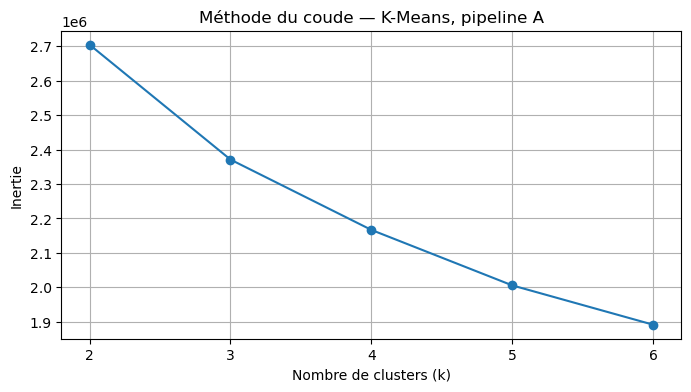

In [16]:
valeurs_k = [2, 3, 4, 5, 6]
inerties_A = []

for k in valeurs_k:
    modele = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modele.fit(X_train_prepare)
    inerties_A.append(modele.inertia_)

    print(f"k = {k} | Inertie = {modele.inertia_:.2f}")

plt.plot(valeurs_k, inerties_A, marker="o")
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Inertie")
plt.title("Méthode du coude — K-Means, pipeline A")
plt.xticks(valeurs_k)
plt.grid(True)
plt.show()

Entraînement de K-Means pour $k=2,3,4,5,6$, puis comparaison des inerties. Une baisse de l’inertie est attendue lorsque $k$ augmente, on cherche un compromis au niveau d’un éventuel « coude », pas simplement la valeur minimale.

---

k = 2 | Silhouette = 0.2965
k = 3 | Silhouette = 0.2999
k = 4 | Silhouette = 0.3114
k = 5 | Silhouette = 0.3222
k = 6 | Silhouette = 0.3195


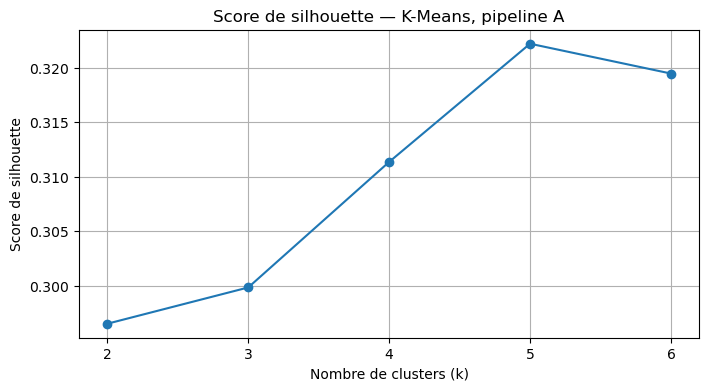

In [17]:
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(42)

indices_echantillon = rng.choice(
    X_train_prepare.shape[0],
    size=3000,
    replace=False
)

X_echantillon = X_train_prepare[indices_echantillon]

scores_silhouette_A = []

for k in valeurs_k:
    modele = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    clusters = modele.fit_predict(X_train_prepare)

    score = silhouette_score(
        X_echantillon,
        clusters[indices_echantillon]
    )

    scores_silhouette_A.append(score)

    print(f"k = {k} | Silhouette = {score:.4f}")

plt.plot(valeurs_k, scores_silhouette_A, marker="o")
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Score de silhouette")
plt.title("Score de silhouette — K-Means, pipeline A")
plt.xticks(valeurs_k)
plt.grid(True)
plt.show()

La silhouette compare la cohésion d’un point avec son cluster et sa séparation des autres : $s(i)=(b(i)-a(i))/\max(a(i),b(i))$. Elle varie entre −1 et 1, plus elle est élevée, plus les groupes sont généralement distincts. Le calcul est effectué sur un échantillon de 3 000 lignes pour limiter le coût.

---

k = 2 | Silhouette = 0.3275 | Inertie = 2565964.53
k = 3 | Silhouette = 0.3244 | Inertie = 2235027.47
k = 4 | Silhouette = 0.3341 | Inertie = 2059988.72
k = 5 | Silhouette = 0.3580 | Inertie = 1893079.54
k = 6 | Silhouette = 0.3581 | Inertie = 1760973.87


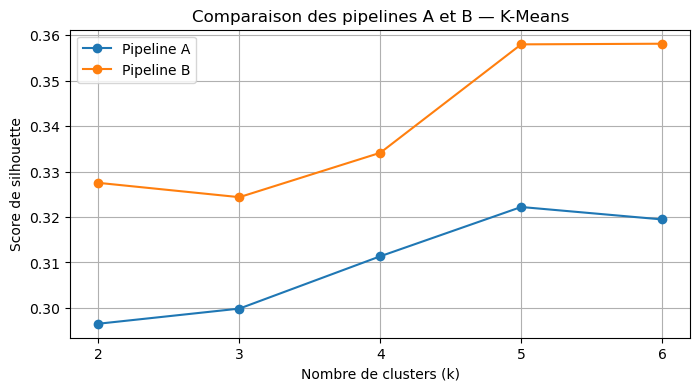

In [18]:
X_echantillon_B = X_train_B[indices_echantillon]

scores_silhouette_B = []
inerties_B = []

for k in valeurs_k:
    modele = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    clusters = modele.fit_predict(X_train_B)

    score = silhouette_score(
        X_echantillon_B,
        clusters[indices_echantillon]
    )

    scores_silhouette_B.append(score)
    inerties_B.append(modele.inertia_)

    print(
        f"k = {k} | "
        f"Silhouette = {score:.4f} | "
        f"Inertie = {modele.inertia_:.2f}"
    )

plt.plot(valeurs_k, scores_silhouette_A, marker="o", label="Pipeline A")
plt.plot(valeurs_k, scores_silhouette_B, marker="o", label="Pipeline B")

plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Score de silhouette")
plt.title("Comparaison des pipelines A et B — K-Means")
plt.xticks(valeurs_k)
plt.legend()
plt.grid(True)
plt.show()

Cette cellule poursuit la comparaison des configurations K-Means du pipeline A. Les scores internes servent à choisir une segmentation interprétable, ils ne remplacent pas une évaluation des anomalies avec les véritables étiquettes.

---

In [19]:
kmeans_B = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

clusters_B = kmeans_B.fit_predict(X_train_B)

repartition_B = pd.Series(clusters_B).value_counts().sort_index()

pourcentages_B = repartition_B / len(clusters_B) * 100

resultats_B = pd.DataFrame({
    "Observations": repartition_B,
    "Pourcentage (%)": pourcentages_B.round(2)
})

print("Répartition des clusters — Pipeline B, k=5 :")
print(resultats_B)

print("\nTotal des observations :", repartition_B.sum())

Répartition des clusters — Pipeline B, k=5 :
   Observations  Pourcentage (%)
0         10429            12.67
1         29270            35.55
2         28334            34.41
3           912             1.11
4         13387            16.26

Total des observations : 82332


Le modèle B est entraîné sur les variables transformées par le pipeline B. La segmentation est ensuite analysée à l’aide de la taille des groupes et des critères internes. L’ajout du logarithme change les distances et peut donc changer les clusters.

---

In [20]:
analyse_clusters_B = X_train[
    ["dur", "spkts", "sbytes", "rate"]
].copy()

analyse_clusters_B["cluster"] = clusters_B

profils_B = analyse_clusters_B.groupby("cluster").median()

print("Médianes des caractéristiques par cluster — Pipeline B :")
print(profils_B.round(4))

print("\nMoyennes des caractéristiques par cluster :")
print(analyse_clusters_B.groupby("cluster").mean().round(2))

Médianes des caractéristiques par cluster — Pipeline B :
            dur  spkts  sbytes         rate
cluster                                    
0        0.0000    2.0   114.0  125000.0003
1        0.0000    2.0   146.0  111111.1072
2        0.7906   10.0   878.0      24.6361
3        0.0000    1.0    46.0       0.0000
4        0.0770   34.0  2766.0    1279.7619

Moyennes des caractéristiques par cluster :
          dur  spkts    sbytes       rate
cluster                                  
0        0.16   2.08    142.83  205510.62
1        0.44   2.70    309.70  157564.53
2        1.94  20.71  12532.37      30.66
3        2.24   1.04     47.71       0.00
4        0.86  63.37  21846.89    2166.29


Les médianes des variables réseau sont calculées par cluster B pour donner une interprétation concrète des groupes obtenus. Une forte valeur de débit ou une faible durée décrit un profil, mais ne prouve pas une attaque.

---

In [21]:
analyse_categories_B = X_train[
    ["proto", "service", "state"]
].copy()

analyse_categories_B["cluster"] = clusters_B

for colonne in ["proto", "service", "state"]:
    print(f"\nRépartition de {colonne} par cluster :")

    tableau = pd.crosstab(
        analyse_categories_B["cluster"],
        analyse_categories_B[colonne],
        normalize="index"
    ) * 100

    for cluster in sorted(analyse_categories_B["cluster"].unique()):
        principales = (
            tableau.loc[cluster]
            .sort_values(ascending=False)
            .head(3)
        )

        print(f"\nCluster {cluster} :")
        print(principales.round(2))


Répartition de proto par cluster :

Cluster 0 :
proto
udp    98.37
tcp     1.63
3pc     0.00
Name: 0, dtype: float64

Cluster 1 :
proto
udp     65.38
unas    12.01
tcp      5.08
Name: 1, dtype: float64

Cluster 2 :
proto
tcp     99.01
ospf     0.66
arp      0.16
Name: 2, dtype: float64

Cluster 3 :
proto
arp    100.0
3pc      0.0
rvd      0.0
Name: 3, dtype: float64

Cluster 4 :
proto
tcp    99.99
udp     0.01
3pc     0.00
Name: 4, dtype: float64

Répartition de service par cluster :

Cluster 0 :
service
dns     95.72
-        4.28
dhcp     0.00
Name: 0, dtype: float64

Cluster 1 :
service
-       60.96
dns     38.82
snmp     0.10
Name: 1, dtype: float64

Cluster 2 :
service
-       67.30
http    21.73
ftp      4.31
Name: 2, dtype: float64

Cluster 3 :
service
-       100.0
dhcp      0.0
dns       0.0
Name: 3, dtype: float64

Cluster 4 :
service
-           66.35
http        15.90
ftp-data     7.20
Name: 4, dtype: float64

Répartition de state par cluster :

Cluster 0 :
state
INT    9

Les catégories `proto`, `service` et `state` sont croisées avec les clusters B. L’objectif est d’identifier des profils techniques dominants et d’expliquer les regroupements sans utiliser `label` dans l’apprentissage.

---

In [22]:
distances_centres_B = kmeans_B.transform(X_train_B)

scores_atypicite_B = distances_centres_B[
    np.arange(X_train_B.shape[0]),
    clusters_B
]

print("Statistiques des distances aux centres :")
print(pd.Series(scores_atypicite_B).describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
).round(4))

print(
    "\nNombre de scores calculés :",
    len(scores_atypicite_B)
)

Statistiques des distances aux centres :
count    82332.0000
mean         3.2819
std          3.4960
min          0.4762
50%          2.6143
90%          5.0997
95%          6.9815
99%         15.6833
max        241.0142
dtype: float64

Nombre de scores calculés : 82332


Chaque observation reçoit sa distance au centre de son cluster : $d_i=\|x_i-\mu_{c_i}\|$. Plus cette distance est grande, plus le profil s’écarte de son groupe. Le **99e percentile** des distances Train vaut environ **15,6833**.

---

In [23]:
seuil_atypicite_B = np.quantile(
    scores_atypicite_B,
    0.99
)

anomalies_train_B = (
    scores_atypicite_B > seuil_atypicite_B
)

resultats_anomalies_B = pd.DataFrame({
    "cluster": clusters_B,
    "score_atypicite": scores_atypicite_B,
    "atypique": anomalies_train_B
})

print("Seuil d'atypicité :", round(seuil_atypicite_B, 4))

print(
    "Nombre de communications atypiques :",
    anomalies_train_B.sum()
)

print(
    "Pourcentage de communications atypiques :",
    round(anomalies_train_B.mean() * 100, 2),
    "%"
)

print("\nCommunications atypiques par cluster :")

print(
    resultats_anomalies_B
    .groupby("cluster")["atypique"]
    .agg(["sum", "count", "mean"])
    .rename(columns={
        "sum": "Atypiques",
        "count": "Total",
        "mean": "Proportion"
    })
    .assign(
        Proportion=lambda x: (
            x["Proportion"] * 100
        ).round(2)
    )
)

Seuil d'atypicité : 15.6833
Nombre de communications atypiques : 824
Pourcentage de communications atypiques : 1.0 %

Communications atypiques par cluster :
         Atypiques  Total  Proportion
cluster                              
0                0  10429        0.00
1               53  29270        0.18
2              506  28334        1.79
3                0    912        0.00
4              265  13387        1.98


Le seuil est fixé au 99e percentile : $t=Q_{0,99}(d_{train})$. Une observation est signalée si $d_i>t$. Cela désigne **824 communications**, soit environ **1 % du Train**. Il s’agit d’anomalies statistiques, pas nécessairement d’attaques.

---

In [24]:
clusters_test_B = kmeans_B.predict(X_test_B)

distances_test_B = kmeans_B.transform(X_test_B)

scores_atypicite_test_B = distances_test_B[
    np.arange(X_test_B.shape[0]),
    clusters_test_B
]

anomalies_test_B = (
    scores_atypicite_test_B > seuil_atypicite_B
)

print("Nombre d'observations Test :", len(clusters_test_B))

print(
    "Nombre de communications atypiques :",
    anomalies_test_B.sum()
)

print(
    "Pourcentage de communications atypiques :",
    round(anomalies_test_B.mean() * 100, 2),
    "%"
)

print("\nStatistiques des scores sur le Test :")

print(
    pd.Series(scores_atypicite_test_B)
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .round(4)
)

Nombre d'observations Test : 175341
Nombre de communications atypiques : 1656
Pourcentage de communications atypiques : 0.94 %

Statistiques des scores sur le Test :
count    175341.0000
mean          3.3810
std           3.7478
min           0.5328
50%           2.7206
90%           5.3750
95%           7.5692
99%          15.6349
max         316.5009
dtype: float64


Le modèle B attribue un cluster à chaque ligne Test, calcule sa distance au centre et applique le **seuil appris sur le Train**. Il signale **1 656 communications**, soit **0,94 % du Test**. Aucun ajustement du modèle n’est réalisé sur le Test.

---

In [25]:
from sklearn.metrics import confusion_matrix, classification_report

y_test_reel = y_test["label"].to_numpy()

y_test_predit = anomalies_test_B.astype(int)

matrice_confusion_B = confusion_matrix(
    y_test_reel,
    y_test_predit,
    labels=[0, 1]
)

print("Matrice de confusion — Test :")
print(matrice_confusion_B)

print("\nRapport de classification :")
print(
    classification_report(
        y_test_reel,
        y_test_predit,
        labels=[0, 1],
        target_names=["Normal", "Attaque"],
        zero_division=0
    )
)

Matrice de confusion — Test :
[[ 55233    767]
 [118452    889]]

Rapport de classification :
              precision    recall  f1-score   support

      Normal       0.32      0.99      0.48     56000
     Attaque       0.54      0.01      0.01    119341

    accuracy                           0.32    175341
   macro avg       0.43      0.50      0.25    175341
weighted avg       0.47      0.32      0.16    175341



Les anomalies prédites sont comparées aux étiquettes binaires réelles : **VP** = attaque détectée, **FP** = trafic normal signalé, **FN** = attaque manquée, **VN** = trafic normal non signalé. La matrice de confusion sert à mesurer l’utilité de la détection.

---

In [26]:
analyse_attaques_B = y_test.copy()

analyse_attaques_B["atypique"] = anomalies_test_B

tableau_attaques_B = (
    analyse_attaques_B
    .groupby("attack_cat")["atypique"]
    .agg(["sum", "count", "mean"])
    .rename(columns={
        "sum": "Alertes",
        "count": "Total",
        "mean": "Taux_detection"
    })
)

tableau_attaques_B["Taux_detection"] = (
    tableau_attaques_B["Taux_detection"] * 100
).round(2)

print("Alertes par catégorie de trafic :")
print(tableau_attaques_B.sort_values("Total", ascending=False))

Alertes par catégorie de trafic :
                Alertes  Total  Taux_detection
attack_cat                                    
Normal              767  56000            1.37
Generic              17  40000            0.04
Exploits            481  33393            1.44
Fuzzers             225  18184            1.24
DoS                  66  12264            0.54
Reconnaissance        4  10491            0.04
Analysis             90   2000            4.50
Backdoor              0   1746            0.00
Shellcode             2   1133            0.18
Worms                 4    130            3.08


La comparaison des prédictions avec `attack_cat` mesure les différences de détection entre familles d’attaques. Les catégories servent **uniquement à l’analyse a posteriori** : elles n’ont pas été utilisées pour créer les clusters.

---

In [27]:
analyse_scores_test_B = y_test.copy()

analyse_scores_test_B["score_atypicite"] = scores_atypicite_test_B

statistiques_scores = (
    analyse_scores_test_B
    .groupby("attack_cat")["score_atypicite"]
    .agg(["count", "median", "mean", "max"])
    .sort_values("median", ascending=False)
)

print("Scores d'atypicité par catégorie :")
print(statistiques_scores.round(4))

print("\nSeuil d'atypicité actuel :", round(seuil_atypicite_B, 4))

Scores d'atypicité par catégorie :
                count  median    mean       max
attack_cat                                     
Normal          56000  3.2974  3.9370   79.8331
Worms             130  3.0375  4.5271   16.4591
Exploits        33393  2.9748  4.0465  316.5009
Generic         40000  2.3401  2.4520  169.1119
Fuzzers         18184  2.2595  3.4830   51.8950
Shellcode        1133  2.0286  2.2449   16.0033
Reconnaissance  10491  1.9536  2.2658   80.5182
Analysis         2000  1.8130  4.4259   47.2072
DoS             12264  1.7739  2.9126  173.7389
Backdoor         1746  1.7553  2.4926   13.6415

Seuil d'atypicité actuel : 15.6833


Les scores d’atypicité sont rapprochés des étiquettes normales/attaques pour vérifier si les attaques tendent à avoir des distances plus élevées. Le recouvrement éventuel des distributions limite l’efficacité d’un seuil unique.

---

In [28]:
from sklearn.metrics import roc_auc_score, average_precision_score

roc_auc_B = roc_auc_score(
    y_test_reel,
    scores_atypicite_test_B
)

ap_B = average_precision_score(
    y_test_reel,
    scores_atypicite_test_B
)

proportion_attaques = y_test_reel.mean()

print("Évaluation des scores d'atypicité — Pipeline B")

print("ROC-AUC :", round(roc_auc_B, 4))
print("Average Precision :", round(ap_B, 4))

print(
    "Proportion d'attaques dans le Test :",
    round(proportion_attaques * 100, 2),
    "%"
)

Évaluation des scores d'atypicité — Pipeline B
ROC-AUC : 0.3161
Average Precision : 0.5905
Proportion d'attaques dans le Test : 68.06 %


**ROC-AUC** évalue le classement des attaques par le score, tous seuils confondus, **Average Precision (AP)** synthétise la courbe précision-rappel. Ces métriques évaluent les scores continus, pas seulement la décision binaire au seuil choisi. Elles sont calculées avec les étiquettes du Test, sans entraîner K-Means avec celles-ci.

---

In [29]:
masque_normal_train = y_train["label"] == 0

X_train_normal = X_train.loc[masque_normal_train].copy()

print("Nombre total de communications Train :", len(X_train))

print(
    "Nombre de communications normales Train :",
    len(X_train_normal)
)

print(
    "Nombre de communications étiquetées comme attaques Train :",
    (~masque_normal_train).sum()
)

print(
    "Pourcentage de trafic normal dans le Train :",
    round(masque_normal_train.mean() * 100, 2),
    "%"
)

print(
    "Dimensions des données normales :",
    X_train_normal.shape
)

Nombre total de communications Train : 82332
Nombre de communications normales Train : 37000
Nombre de communications étiquetées comme attaques Train : 45332
Pourcentage de trafic normal dans le Train : 44.94 %
Dimensions des données normales : (37000, 42)


Le masque `label == 0` isole les **37 000 communications normales du Train**. Cette étape introduit une hypothèse de **détection de nouveauté** : apprendre le trafic normal, puis considérer les écarts comme suspects. Elle utilise les étiquettes pour sélectionner les exemples d’entraînement ; le modèle n’est donc plus entièrement non supervisé au sens strict du protocole.

---

In [30]:
from sklearn.base import clone

preprocesseur_C = clone(preprocesseur_B)

X_train_normal_C = preprocesseur_C.fit_transform(
    X_train_normal
)

print(
    "Dimensions des données normales initiales :",
    X_train_normal.shape
)

print(
    "Dimensions après prétraitement :",
    X_train_normal_C.shape
)

print(
    "Nombre de caractéristiques :",
    X_train_normal_C.shape[1]
)

print(
    "Valeurs non finies :",
    not np.isfinite(X_train_normal_C.data).all()
)

Dimensions des données normales initiales : (37000, 42)
Dimensions après prétraitement : (37000, 58)
Nombre de caractéristiques : 58
Valeurs non finies : False


`clone(preprocesseur_B)` crée une nouvelle instance avec les mêmes réglages mais **sans paramètres déjà appris**. Elle pourra être ajustée exclusivement sur les communications normales, sans réutiliser les statistiques calculées sur tout le Train.

---

In [31]:
kmeans_C = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

clusters_normal_C = kmeans_C.fit_predict(
    X_train_normal_C
)

repartition_C = (
    pd.Series(clusters_normal_C)
    .value_counts()
    .sort_index()
)

print("Nombre de clusters :", kmeans_C.n_clusters)

print("\nRépartition des communications normales :")
print(repartition_C)

print(
    "\nTotal des communications :",
    repartition_C.sum()
)

print(
    "\nInertie du modèle :",
    round(kmeans_C.inertia_, 2)
)

Nombre de clusters : 5

Répartition des communications normales :
0      510
1    13999
2     9371
3    11730
4     1390
Name: count, dtype: int64

Total des communications : 37000

Inertie du modèle : 931301.12


K-Means est ajusté uniquement sur les profils normaux prétraités. Ses centres représentent des profils de trafic considérés comme habituels. Une observation éloignée de ces centres devient une candidate à l’anomalie.

---

In [32]:
analyse_clusters_C = X_train_normal[
    ["dur", "spkts", "sbytes", "rate"]
].copy()

analyse_clusters_C["cluster"] = clusters_normal_C

profils_C = (
    analyse_clusters_C
    .groupby("cluster")
    .median()
)

print("Médianes des caractéristiques par cluster — Modèle C :")
print(profils_C.round(4))

print("\nMoyennes des caractéristiques par cluster :")

print(
    analyse_clusters_C
    .groupby("cluster")
    .mean()
    .round(2)
)

Médianes des caractéristiques par cluster — Modèle C :
            dur  spkts   sbytes         rate
cluster                                     
0        3.3857  328.0  17609.0     257.3830
1        0.7940   10.0    828.0      21.9414
2        0.0009    2.0    132.0    2999.9999
3        0.0463   34.0   2766.0    1699.2354
4        0.0000    2.0    951.0  100000.0025

Moyennes des caractéristiques par cluster :
          dur   spkts    sbytes       rate
cluster                                   
0        5.80  318.41  17668.14     557.75
1        1.35   12.95   4791.32      24.39
2        0.69    2.23    274.92   92855.01
3        0.37   40.30   6052.09    2436.97
4        3.54    3.87    738.29  107621.34


Les médianes par cluster décrivent les types de trafic normal appris par C. Cette lecture permet de vérifier que les groupes ont une interprétation technique cohérente.

---

In [33]:
analyse_categories_C = X_train_normal[
    ["proto", "service", "state"]
].copy()

analyse_categories_C["cluster"] = clusters_normal_C

for colonne in ["proto", "service", "state"]:

    print(f"\nRépartition de {colonne} par cluster :")

    tableau = pd.crosstab(
        analyse_categories_C["cluster"],
        analyse_categories_C[colonne],
        normalize="index"
    ) * 100

    for cluster in sorted(analyse_categories_C["cluster"].unique()):

        principales = (
            tableau.loc[cluster]
            .sort_values(ascending=False)
            .head(3)
        )

        print(f"\nCluster {cluster} :")
        print(principales.round(2))


Répartition de proto par cluster :

Cluster 0 :
proto
tcp     100.0
arp       0.0
igmp      0.0
Name: 0, dtype: float64

Cluster 1 :
proto
tcp     100.0
arp       0.0
igmp      0.0
Name: 1, dtype: float64

Cluster 2 :
proto
udp    77.08
tcp    11.66
arp    10.53
Name: 2, dtype: float64

Cluster 3 :
proto
tcp     100.0
arp       0.0
igmp      0.0
Name: 3, dtype: float64

Cluster 4 :
proto
udp    62.88
tcp    37.12
arp     0.00
Name: 4, dtype: float64

Répartition de service par cluster :

Cluster 0 :
service
-       66.86
http    33.14
dns      0.00
Name: 0, dtype: float64

Cluster 1 :
service
-       80.11
http    16.83
ftp      3.06
Name: 1, dtype: float64

Cluster 2 :
service
-         67.24
dns       32.74
radius     0.02
Name: 2, dtype: float64

Cluster 3 :
service
-           69.30
http        12.69
ftp-data     8.09
Name: 3, dtype: float64

Cluster 4 :
service
-      100.0
dns      0.0
ftp      0.0
Name: 4, dtype: float64

Répartition de state par cluster :

Cluster 0 :
state
FI

Les répartitions de `proto`, `service` et `state` par cluster C permettent de distinguer les usages réseau courants parmi les communications normales. Aucun cluster n’est intrinsèquement une catégorie d’attaque.

---

In [34]:
distances_centres_C = kmeans_C.transform(X_train_normal_C)

scores_atypicite_C = distances_centres_C[
    np.arange(X_train_normal_C.shape[0]),
    clusters_normal_C
]

print("Statistiques des distances aux centres - Modèle C :")

print(
    pd.Series(scores_atypicite_C)
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .round(4)
)

print(
    "\nNombre de scores calculés :",
    len(scores_atypicite_C)
)

Statistiques des distances aux centres - Modèle C :
count    37000.0000
mean         4.0794
std          2.9204
min          1.2399
50%          3.3318
90%          7.0461
95%          9.0808
99%         14.6596
max        105.2279
dtype: float64

Nombre de scores calculés : 37000


Pour chaque profil normal, calcul de la distance au centre du cluster attribué. Cette distribution de référence est utilisée pour calibrer le seuil de détection.

---

In [35]:
seuil_atypicite_C = np.quantile(
    scores_atypicite_C,
    0.99
)

anomalies_train_C = (
    scores_atypicite_C > seuil_atypicite_C
)

resultats_anomalies_C = pd.DataFrame({
    "cluster": clusters_normal_C,
    "score_atypicite": scores_atypicite_C,
    "atypique": anomalies_train_C
})

print(
    "Seuil d'atypicité du modèle C :",
    round(seuil_atypicite_C, 4)
)

print(
    "Nombre de communications normales considérées atypiques :",
    anomalies_train_C.sum()
)

print(
    "Pourcentage de communications normales considérées atypiques :",
    round(anomalies_train_C.mean() * 100, 2),
    "%"
)

print("\nCommunications atypiques par cluster :")

print(
    resultats_anomalies_C
    .groupby("cluster")["atypique"]
    .agg(["sum", "count", "mean"])
    .rename(columns={
        "sum": "Atypiques",
        "count": "Total",
        "mean": "Proportion"
    })
    .assign(
        Proportion=lambda x: (
            x["Proportion"] * 100
        ).round(2)
    )
)

Seuil d'atypicité du modèle C : 14.6596
Nombre de communications normales considérées atypiques : 370
Pourcentage de communications normales considérées atypiques : 1.0 %

Communications atypiques par cluster :
         Atypiques  Total  Proportion
cluster                              
0               20    510        3.92
1              271  13999        1.94
2               49   9371        0.52
3               25  11730        0.21
4                5   1390        0.36


Le seuil est défini à partir d’un percentile élevé des scores normaux d’apprentissage. Un score supérieur indique une observation éloignée des profils normaux connus. Le percentile contrôle la sévérité du seuil sur la population de référence, pas le taux garanti de fausses alertes sur un autre jeu.

---

In [36]:
X_test_C = preprocesseur_C.transform(X_test)

clusters_test_C = kmeans_C.predict(X_test_C)

distances_test_C = kmeans_C.transform(X_test_C)

scores_atypicite_test_C = distances_test_C[
    np.arange(X_test_C.shape[0]),
    clusters_test_C
]

anomalies_test_C = (
    scores_atypicite_test_C > seuil_atypicite_C
)

print("Dimensions du Test préparé :", X_test_C.shape)

print(
    "Nombre de communications Test :",
    len(clusters_test_C)
)

print(
    "Nombre de communications atypiques :",
    anomalies_test_C.sum()
)

print(
    "Pourcentage de communications atypiques :",
    round(anomalies_test_C.mean() * 100, 2),
    "%"
)

print("\nStatistiques des scores sur le Test :")

print(
    pd.Series(scores_atypicite_test_C)
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .round(4)
)

Dimensions du Test préparé : (175341, 58)
Nombre de communications Test : 175341
Nombre de communications atypiques : 39969
Pourcentage de communications atypiques : 22.8 %

Statistiques des scores sur le Test :
count    175341.0000
mean         12.8151
std          18.3991
min           1.2404
50%           4.2644
90%          44.9466
95%          47.9849
99%          53.4431
max         611.1675
dtype: float64


Le préprocesseur et K-Means C, ajustés sur les communications normales du Train, sont appliqués aux **175 341 observations du Test**. Le score de distance est comparé au seuil fixé pour produire les alertes.

---

In [37]:
y_test_predit_C = anomalies_test_C.astype(int)

matrice_confusion_C = confusion_matrix(
    y_test_reel,
    y_test_predit_C,
    labels=[0, 1]
)

print("Matrice de confusion - Modèle C :")
print(matrice_confusion_C)

print("\nRapport de classification - Modèle C :")

print(
    classification_report(
        y_test_reel,
        y_test_predit_C,
        labels=[0, 1],
        target_names=["Normal", "Attaque"],
        zero_division=0
    )
)

Matrice de confusion - Modèle C :
[[55440   560]
 [79932 39409]]

Rapport de classification - Modèle C :
              precision    recall  f1-score   support

      Normal       0.41      0.99      0.58     56000
     Attaque       0.99      0.33      0.49    119341

    accuracy                           0.54    175341
   macro avg       0.70      0.66      0.54    175341
weighted avg       0.80      0.54      0.52    175341



Les booléens d’anomalie sont convertis en 0/1, puis comparés aux étiquettes réelles. **Précision** $=VP/(VP+FP)$ ; **rappel** $=VP/(VP+FN)$ ; **F1** $=2PR/(P+R)$. La précision mesure la fiabilité des alertes ; le rappel mesure la proportion d’attaques retrouvées.

---

In [38]:
analyse_attaques_C = y_test.copy()

analyse_attaques_C["atypique"] = anomalies_test_C

tableau_attaques_C = (
    analyse_attaques_C
    .groupby("attack_cat")["atypique"]
    .agg(["sum", "count", "mean"])
    .rename(columns={
        "sum": "Alertes",
        "count": "Total",
        "mean": "Taux_detection"
    })
)

tableau_attaques_C["Taux_detection"] = (
    tableau_attaques_C["Taux_detection"] * 100
).round(2)

print("Alertes par catégorie de trafic - Modèle C :")

print(
    tableau_attaques_C.sort_values(
        "Total",
        ascending=False
    )
)

Alertes par catégorie de trafic - Modèle C :
                Alertes  Total  Taux_detection
attack_cat                                    
Normal              560  56000            1.00
Generic           37003  40000           92.51
Exploits           1142  33393            3.42
Fuzzers             524  18184            2.88
DoS                 487  12264            3.97
Reconnaissance       60  10491            0.57
Analysis            146   2000            7.30
Backdoor             45   1746            2.58
Shellcode             2   1133            0.18
Worms                 0    130            0.00


La performance du modèle C est examinée par famille d’attaque. Des rappels différents révèlent que certaines attaques ressemblent davantage au trafic normal dans l’espace des caractéristiques.

---

In [39]:
analyse_scores_test_C = y_test.copy()

analyse_scores_test_C["score_atypicite"] = scores_atypicite_test_C

statistiques_scores_C = (
    analyse_scores_test_C
    .groupby("attack_cat")["score_atypicite"]
    .agg(["count", "median", "mean", "max"])
    .sort_values("median", ascending=False)
)

print("Scores d'atypicité par catégorie - Modèle C :")

print(statistiques_scores_C.round(4))

print(
    "\nSeuil d'atypicité du modèle C :",
    round(seuil_atypicite_C, 4)
)

Scores d'atypicité par catégorie - Modèle C :
                count   median     mean       max
attack_cat                                       
Generic         40000  44.9069  38.8620  196.9091
Analysis         2000   4.6506   6.8870   39.8003
Exploits        33393   4.0505   6.5145  611.1675
DoS             12264   4.0240   6.4622  512.8795
Backdoor         1746   3.8760   5.3545   27.1174
Worms             130   3.7759   4.9567   10.5658
Normal          56000   3.2157   4.4844  137.4464
Fuzzers         18184   2.8657   4.4669  103.2037
Reconnaissance  10491   2.5943   3.4634  100.9346
Shellcode        1133   2.5375   2.9060   15.4892

Seuil d'atypicité du modèle C : 14.6596


Le rapprochement des scores continus et des étiquettes réelles permet de comprendre les recouvrements entre trafic normal et attaques. Il prépare l’évaluation indépendante d’un seuil particulier.

---

In [40]:
roc_auc_C = roc_auc_score(
    y_test_reel,
    scores_atypicite_test_C
)

ap_C = average_precision_score(
    y_test_reel,
    scores_atypicite_test_C
)

print("Évaluation des scores d'atypicité - Modèle C")

print("ROC-AUC :", round(roc_auc_C, 4))
print("Average Precision :", round(ap_C, 4))

print(
    "Proportion d'attaques dans le Test :",
    round(y_test_reel.mean() * 100, 2),
    "%"
)

print("\nComparaison des modèles B et C :")

comparaison_scores = pd.DataFrame({
    "Modèle": ["B", "C"],
    "ROC-AUC": [roc_auc_B, roc_auc_C],
    "Average Precision": [ap_B, ap_C]
})

print(comparaison_scores.round(4))

Évaluation des scores d'atypicité - Modèle C
ROC-AUC : 0.7162
Average Precision : 0.8586
Proportion d'attaques dans le Test : 68.06 %

Comparaison des modèles B et C :
  Modèle  ROC-AUC  Average Precision
0      B   0.3161             0.5905
1      C   0.7162             0.8586


Calcul de **ROC-AUC** et **Average Precision** pour C à partir des scores d’atypicité. Ces métriques permettent de comparer les capacités de classement des modèles même si leurs seuils de décision diffèrent.

---

In [41]:
from sklearn.metrics import precision_score, recall_score, f1_score

percentiles_C = [0.90, 0.95, 0.97, 0.99, 0.995]

resultats_seuils_C = []

for percentile in percentiles_C:

    seuil = np.quantile(scores_atypicite_C, percentile)

    predictions = (
        scores_atypicite_test_C > seuil
    ).astype(int)

    resultats_seuils_C.append({
        "Percentile": percentile * 100,
        "Seuil": seuil,
        "Alertes (%)": predictions.mean() * 100,
        "Précision": precision_score(
            y_test_reel, predictions, zero_division=0
        ),
        "Rappel": recall_score(
            y_test_reel, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test_reel, predictions, zero_division=0
        )
    })

tableau_seuils_C = pd.DataFrame(resultats_seuils_C)

print("Comparaison des seuils du modèle C :")
print(tableau_seuils_C.round(4))

Comparaison des seuils du modèle C :
   Percentile    Seuil  Alertes (%)  Précision  Rappel  F1-score
0        90.0   7.0461      33.3151     0.8800  0.4307    0.5784
1        95.0   9.0808      29.4911     0.9131  0.3956    0.5521
2        97.0  11.8115      25.5360     0.9509  0.3568    0.5189
3        99.0  14.6596      22.7950     0.9860  0.3302    0.4947
4        99.5  18.2652      21.4804     0.9893  0.3122    0.4746


Comparaison des percentiles **90, 95, 97, 99 et 99,5**. Lorsque le seuil augmente, les alertes deviennent moins nombreuses et souvent plus précises, mais le rappel diminue. **Attention méthodologique :** ces résultats sur le Test sont une analyse de sensibilité, ils ne doivent pas servir à optimiser définitivement le seuil sur ce même Test.

---

In [42]:
from sklearn.metrics import confusion_matrix

comparaison_erreurs_C = []

for percentile in percentiles_C:

    seuil = np.quantile(scores_atypicite_C, percentile)

    predictions = (
        scores_atypicite_test_C > seuil
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_reel,
        predictions,
        labels=[0, 1]
    ).ravel()

    comparaison_erreurs_C.append({
        "Percentile": percentile * 100,
        "Vrais positifs": tp,
        "Faux positifs": fp,
        "Faux négatifs": fn,
        "Vrais négatifs": tn
    })

tableau_erreurs_C = pd.DataFrame(comparaison_erreurs_C)

print("Erreurs de détection selon le seuil :")
print(tableau_erreurs_C)

Erreurs de détection selon le seuil :
   Percentile  Vrais positifs  Faux positifs  Faux négatifs  Vrais négatifs
0        90.0           51406           7009          67935           48991
1        95.0           47215           4495          72126           51505
2        97.0           42577           2198          76764           53802
3        99.0           39409            560          79932           55440
4        99.5           37260            404          82081           55596


Le tableau décompose chaque seuil en **VP, FP, FN et VN**. Au 99e percentile, C détecte **39 409 attaques**, en manque **79 932** et produit **560 fausses alertes**. Ces chiffres rendent visible le compromis entre surcharge d’analyse et attaques non détectées.

---

In [43]:
from sklearn.model_selection import train_test_split

X_normal_apprentissage, X_normal_validation = train_test_split(
    X_train_normal,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print(
    "Communications normales pour l'apprentissage :",
    X_normal_apprentissage.shape
)

print(
    "Communications normales pour la validation :",
    X_normal_validation.shape
)

print(
    "Total :",
    len(X_normal_apprentissage) + len(X_normal_validation)
)

Communications normales pour l'apprentissage : (29600, 42)
Communications normales pour la validation : (7400, 42)
Total : 37000


Les **37 000 profils normaux du Train** sont séparés en **29 600 pour l’apprentissage** et **7 400 pour la validation** (80/20). La validation sert à fixer le seuil **sans utiliser le Test**, ce qui renforce la rigueur de la comparaison.

---

In [44]:
preprocesseur_D = clone(preprocesseur_B)

X_apprentissage_D = preprocesseur_D.fit_transform(
    X_normal_apprentissage
)

X_validation_D = preprocesseur_D.transform(
    X_normal_validation
)

print(
    "Dimensions de l'apprentissage :",
    X_apprentissage_D.shape
)

print(
    "Dimensions de la validation :",
    X_validation_D.shape
)

print(
    "Même nombre de caractéristiques :",
    X_apprentissage_D.shape[1] == X_validation_D.shape[1]
)

print(
    "Valeurs non finies dans l'apprentissage :",
    not np.isfinite(X_apprentissage_D.data).all()
)

print(
    "Valeurs non finies dans la validation :",
    not np.isfinite(X_validation_D.data).all()
)

Dimensions de l'apprentissage : (29600, 57)
Dimensions de la validation : (7400, 57)
Même nombre de caractéristiques : True
Valeurs non finies dans l'apprentissage : False
Valeurs non finies dans la validation : False


Un nouveau préprocesseur est ajusté uniquement sur les 29 600 profils d’apprentissage puis appliqué aux 7 400 profils de validation. Il produit **57 caractéristiques**. La différence avec les 190 précédentes vient notamment des catégories observées dans ce sous-ensemble normal.

---

In [45]:
kmeans_D = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

clusters_apprentissage_D = kmeans_D.fit_predict(
    X_apprentissage_D
)

repartition_D = (
    pd.Series(clusters_apprentissage_D)
    .value_counts()
    .sort_index()
)

print("Nombre de clusters :", kmeans_D.n_clusters)

print("\nRépartition des communications normales :")
print(repartition_D)

print(
    "\nTotal des communications :",
    repartition_D.sum()
)

print(
    "\nInertie du modèle :",
    round(kmeans_D.inertia_, 2)
)

Nombre de clusters : 5

Répartition des communications normales :
0    11106
1     9581
2      752
3     7925
4      236
Name: count, dtype: int64

Total des communications : 29600

Inertie du modèle : 753813.37


K-Means à **5 clusters** apprend les profils normaux sur l’ensemble d’apprentissage D. L’inertie est **753 813,37**, sa valeur brute ne doit pas être comparée directement à celle de modèles entraînés sur des données ou espaces différents.

---

In [46]:
clusters_validation_D = kmeans_D.predict(
    X_validation_D
)

distances_validation_D = kmeans_D.transform(
    X_validation_D
)

scores_atypicite_validation_D = distances_validation_D[
    np.arange(X_validation_D.shape[0]),
    clusters_validation_D
]

print("Statistiques des scores sur la validation :")

print(
    pd.Series(scores_atypicite_validation_D)
    .describe(percentiles=[0.90, 0.95, 0.97, 0.99, 0.995])
    .round(4)
)

print(
    "\nNombre de scores calculés :",
    len(scores_atypicite_validation_D)
)

print(
    "Tous les scores sont finis :",
    np.isfinite(scores_atypicite_validation_D).all()
)

Statistiques des scores sur la validation :
count    7400.0000
mean        4.0493
std         3.0927
min         1.1452
50%         3.2716
90%         6.7136
95%         9.6731
97%        11.8512
99%        15.3406
99.5%      18.2572
max       119.4300
dtype: float64

Nombre de scores calculés : 7400
Tous les scores sont finis : True


Le modèle attribue un cluster aux 7 400 observations normales de validation et calcule leur distance au centre. Le **95e percentile** des scores de validation vaut environ **9,6731**.

---

In [47]:
percentiles_D = [0.90, 0.95, 0.97, 0.99, 0.995]

resultats_calibration_D = []

for percentile in percentiles_D:

    seuil = np.quantile(
        scores_atypicite_validation_D,
        percentile
    )

    alertes_validation = (
        scores_atypicite_validation_D > seuil
    )

    resultats_calibration_D.append({
        "Percentile": percentile * 100,
        "Seuil": seuil,
        "Taux d'alertes validation (%)":
            alertes_validation.mean() * 100,
        "Alertes validation":
            alertes_validation.sum()
    })

tableau_calibration_D = pd.DataFrame(
    resultats_calibration_D
)

print("Calibration des seuils - Modèle D :")
print(tableau_calibration_D.round(4))

Calibration des seuils - Modèle D :
   Percentile    Seuil  Taux d'alertes validation (%)  Alertes validation
0        90.0   6.7136                        10.0000                 740
1        95.0   9.6731                         5.0000                 370
2        97.0  11.8512                         3.0000                 222
3        99.0  15.3406                         1.0000                  74
4        99.5  18.2572                         0.4865                  36


Les percentiles 90, 95, 97, 99 et 99,5 sont évalués **sur la validation normale**. Au 95e percentile, **370 profils sur 7 400**, soit **5 %**, dépassent le seuil. Ce taux concerne cette validation, pas nécessairement un réseau réel ou le Test.

---

In [48]:
percentile_retenu_D = 0.95

seuil_atypicite_D = np.quantile(
    scores_atypicite_validation_D,
    percentile_retenu_D
)

alertes_validation_D = (
    scores_atypicite_validation_D > seuil_atypicite_D
)

print("Modèle retenu : D")

print(
    "Percentile retenu :",
    percentile_retenu_D * 100,
    "%"
)

print(
    "Seuil d'atypicité :",
    round(seuil_atypicite_D, 4)
)

print(
    "Nombre de fausses alertes en validation :",
    alertes_validation_D.sum()
)

print(
    "Taux de fausses alertes en validation :",
    round(alertes_validation_D.mean() * 100, 2),
    "%"
)

Modèle retenu : D
Percentile retenu : 95.0 %
Seuil d'atypicité : 9.6731
Nombre de fausses alertes en validation : 370
Taux de fausses alertes en validation : 5.0 %


Le **95e percentile** est retenu, soit un seuil d’environ **9,6731**. Le choix traduit un compromis opérationnel : accepter davantage d’alertes pour accroître la sensibilité. Il est fixé **avant l’évaluation finale sur le Test**.

---

In [49]:
X_test_D = preprocesseur_D.transform(X_test)

clusters_test_D = kmeans_D.predict(X_test_D)

distances_test_D = kmeans_D.transform(X_test_D)

scores_atypicite_test_D = distances_test_D[
    np.arange(X_test_D.shape[0]),
    clusters_test_D
]

anomalies_test_D = (
    scores_atypicite_test_D > seuil_atypicite_D
)

print("Dimensions du Test préparé :", X_test_D.shape)

print(
    "Nombre de communications Test :",
    len(clusters_test_D)
)

print(
    "Nombre de communications atypiques :",
    anomalies_test_D.sum()
)

print(
    "Pourcentage de communications atypiques :",
    round(anomalies_test_D.mean() * 100, 2),
    "%"
)

print("\nStatistiques des scores sur le Test :")

print(
    pd.Series(scores_atypicite_test_D)
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .round(4)
)

Dimensions du Test préparé : (175341, 57)
Nombre de communications Test : 175341
Nombre de communications atypiques : 47255
Pourcentage de communications atypiques : 26.95 %

Statistiques des scores sur le Test :
count    175341.0000
mean         13.0652
std          18.8660
min           1.1451
50%           4.1146
90%          46.0496
95%          49.2649
99%          55.3945
max         615.9417
dtype: float64


Le Test est transformé sans réapprentissage, puis chaque observation reçoit un score et une décision. D signale **47 255 communications sur 175 341**, soit **26,95 %**. Ce taux global d’alertes n’est pas un taux de fausses alertes.

---

In [50]:
y_test_predit_D = anomalies_test_D.astype(int)

matrice_confusion_D = confusion_matrix(
    y_test_reel,
    y_test_predit_D,
    labels=[0, 1]
)

print("Matrice de confusion - Modèle D :")
print(matrice_confusion_D)

print("\nRapport de classification - Modèle D :")

print(
    classification_report(
        y_test_reel,
        y_test_predit_D,
        labels=[0, 1],
        target_names=["Normal", "Attaque"],
        zero_division=0
    )
)

Matrice de confusion - Modèle D :
[[53138  2862]
 [74948 44393]]

Rapport de classification - Modèle D :
              precision    recall  f1-score   support

      Normal       0.41      0.95      0.58     56000
     Attaque       0.94      0.37      0.53    119341

    accuracy                           0.56    175341
   macro avg       0.68      0.66      0.56    175341
weighted avg       0.77      0.56      0.55    175341



La matrice de confusion confronte les alertes D à la réalité. Elle permet de distinguer attaques détectées, attaques manquées et fausses alertes, au lieu de se limiter au nombre total de communications atypiques.

---

In [51]:
analyse_attaques_D = y_test.copy()

analyse_attaques_D["atypique"] = anomalies_test_D

tableau_attaques_D = (
    analyse_attaques_D
    .groupby("attack_cat")["atypique"]
    .agg(["sum", "count", "mean"])
    .rename(columns={
        "sum": "Alertes",
        "count": "Total",
        "mean": "Taux_detection"
    })
)

tableau_attaques_D["Taux_detection"] = (
    tableau_attaques_D["Taux_detection"] * 100
).round(2)

print("Alertes par catégorie de trafic - Modèle D :")

print(
    tableau_attaques_D.sort_values(
        "Total",
        ascending=False
    )
)

Alertes par catégorie de trafic - Modèle D :
                Alertes  Total  Taux_detection
attack_cat                                    
Normal             2862  56000            5.11
Generic           38192  40000           95.48
Exploits           3295  33393            9.87
Fuzzers            1561  18184            8.58
DoS                 832  12264            6.78
Reconnaissance      161  10491            1.53
Analysis            243   2000           12.15
Backdoor             95   1746            5.44
Shellcode             6   1133            0.53
Worms                 8    130            6.15


Analyse des attaques retrouvées et manquées dans chaque catégorie (`attack_cat`). Elle permet d’identifier les familles pour lesquelles la détection est relativement efficace ou difficile.

---

In [52]:
roc_auc_D = roc_auc_score(
    y_test_reel,
    scores_atypicite_test_D
)

ap_D = average_precision_score(
    y_test_reel,
    scores_atypicite_test_D
)

print("Évaluation des scores d'atypicité - Modèle D")

print("ROC-AUC :", round(roc_auc_D, 4))
print("Average Precision :", round(ap_D, 4))

print("\nComparaison des modèles B, C et D :")

comparaison_scores_BCD = pd.DataFrame({
    "Modèle": ["B", "C", "D"],
    "ROC-AUC": [roc_auc_B, roc_auc_C, roc_auc_D],
    "Average Precision": [ap_B, ap_C, ap_D]
})

print(comparaison_scores_BCD.round(4))

Évaluation des scores d'atypicité - Modèle D
ROC-AUC : 0.7269
Average Precision : 0.8654

Comparaison des modèles B, C et D :
  Modèle  ROC-AUC  Average Precision
0      B   0.3161             0.5905
1      C   0.7162             0.8586
2      D   0.7269             0.8654


Calcul de ROC-AUC et d’Average Precision pour D à partir de ses distances aux centres. Ces mesures évaluent sa capacité à attribuer des scores plus élevés aux attaques, indépendamment du seuil retenu.

---

In [53]:
from sklearn.metrics import precision_score, recall_score, f1_score

comparaison_seuils_D = []

for percentile in percentiles_D:

    seuil = np.quantile(
        scores_atypicite_validation_D,
        percentile
    )

    predictions = (
        scores_atypicite_test_D > seuil
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_reel,
        predictions,
        labels=[0, 1]
    ).ravel()

    comparaison_seuils_D.append({
        "Percentile": percentile * 100,
        "Seuil": seuil,
        "Alertes (%)": predictions.mean() * 100,
        "Précision": precision_score(
            y_test_reel, predictions, zero_division=0
        ),
        "Rappel": recall_score(
            y_test_reel, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test_reel, predictions, zero_division=0
        ),
        "Faux positifs": fp,
        "Faux négatifs": fn
    })

tableau_seuils_D = pd.DataFrame(comparaison_seuils_D)

print("Comparaison des seuils - Modèle D :")
print(tableau_seuils_D.round(4))

Comparaison des seuils - Modèle D :
   Percentile    Seuil  Alertes (%)  Précision  Rappel  F1-score  \
0        90.0   6.7136      33.5079     0.8988  0.4425    0.5930   
1        95.0   9.6731      26.9503     0.9394  0.3720    0.5329   
2        97.0  11.8512      25.5485     0.9553  0.3586    0.5214   
3        99.0  15.3406      22.5703     0.9837  0.3262    0.4899   
4        99.5  18.2572      21.6709     0.9891  0.3149    0.4777   

   Faux positifs  Faux négatifs  
0           5944          66532  
1           2862          74948  
2           2004          76548  
3            647          80413  
4            414          81757  


Précision, rappel et F1-score sont comparés sur les mêmes étiquettes Test. **C : précision 98,60 %, rappel 33,02 % ; D : précision 93,94 %, rappel 37,20 %.** D détecte davantage d’attaques mais émet proportionnellement davantage de fausses alertes.

---

In [54]:
comparaison_predictions_CD = pd.DataFrame({
    "Reel": y_test_reel,
    "Alerte_C": anomalies_test_C,
    "Alerte_D": anomalies_test_D
})

attaques_reelles = comparaison_predictions_CD[
    comparaison_predictions_CD["Reel"] == 1
]

print("Comparaison des attaques détectées :")

print(
    pd.crosstab(
        attaques_reelles["Alerte_C"],
        attaques_reelles["Alerte_D"],
        rownames=["Modèle C"],
        colnames=["Modèle D"]
    )
)

print(
    "\nAttaques détectées uniquement par C :",
    ((attaques_reelles["Alerte_C"]) &
     (~attaques_reelles["Alerte_D"])).sum()
)

print(
    "Attaques détectées uniquement par D :",
    ((~attaques_reelles["Alerte_C"]) &
     (attaques_reelles["Alerte_D"])).sum()
)

print(
    "Attaques détectées par les deux modèles :",
    ((attaques_reelles["Alerte_C"]) &
     (attaques_reelles["Alerte_D"])).sum()
)

Comparaison des attaques détectées :
Modèle D  False  True 
Modèle C              
False     74948   4984
True          0  39409

Attaques détectées uniquement par C : 0
Attaques détectées uniquement par D : 4984
Attaques détectées par les deux modèles : 39409


Construction d’un tableau associant, pour chaque communication Test, sa véritable étiquette et les décisions de C et D. Cette analyse identifie les observations détectées par les deux modèles ou par un seul.

---

In [55]:
communications_normales = comparaison_predictions_CD[
    comparaison_predictions_CD["Reel"] == 0
]

print("Comparaison des alertes sur le trafic normal :")

print(
    pd.crosstab(
        communications_normales["Alerte_C"],
        communications_normales["Alerte_D"],
        rownames=["Modèle C"],
        colnames=["Modèle D"]
    )
)

print(
    "\nFausses alertes uniquement par C :",
    (
        communications_normales["Alerte_C"]
        & ~communications_normales["Alerte_D"]
    ).sum()
)

print(
    "Fausses alertes uniquement par D :",
    (
        ~communications_normales["Alerte_C"]
        & communications_normales["Alerte_D"]
    ).sum()
)

print(
    "Fausses alertes communes aux deux modèles :",
    (
        communications_normales["Alerte_C"]
        & communications_normales["Alerte_D"]
    ).sum()
)

Comparaison des alertes sur le trafic normal :
Modèle D  False  True 
Modèle C              
False     53138   2302
True          0    560

Fausses alertes uniquement par C : 0
Fausses alertes uniquement par D : 2302
Fausses alertes communes aux deux modèles : 560


Les observations réellement normales sont isolées pour comparer les alertes injustifiées de C et D. Cette étape est importante car chaque fausse alerte peut mobiliser du temps d’investigation.

---

In [56]:
comparaison_categories_CD = y_test.copy()

comparaison_categories_CD["Alerte_C"] = anomalies_test_C
comparaison_categories_CD["Alerte_D"] = anomalies_test_D

attaques_uniquement_D = comparaison_categories_CD[
    (comparaison_categories_CD["label"] == 1)
    & (~comparaison_categories_CD["Alerte_C"])
    & (comparaison_categories_CD["Alerte_D"])
]

repartition_uniquement_D = (
    attaques_uniquement_D["attack_cat"]
    .value_counts()
    .rename_axis("Catégorie")
    .reset_index(name="Attaques supplémentaires")
)

repartition_uniquement_D["Pourcentage (%)"] = (
    repartition_uniquement_D["Attaques supplémentaires"]
    / len(attaques_uniquement_D)
    * 100
).round(2)

print("Attaques détectées uniquement par le modèle D :")
print(repartition_uniquement_D)

print(
    "\nTotal des attaques supplémentaires :",
    len(attaques_uniquement_D)
)

Attaques détectées uniquement par le modèle D :
        Catégorie  Attaques supplémentaires  Pourcentage (%)
0        Exploits                      2153            43.20
1         Generic                      1189            23.86
2         Fuzzers                      1037            20.81
3             DoS                       345             6.92
4  Reconnaissance                       101             2.03
5        Analysis                        97             1.95
6        Backdoor                        50             1.00
7           Worms                         8             0.16
8       Shellcode                         4             0.08

Total des attaques supplémentaires : 4984


Les résultats C et D sont croisés avec les catégories d’attaque afin de mesurer les détections propres à chaque modèle et leurs éventuelles différences.

---

In [57]:
comparaison_categories = y_test.copy()

comparaison_categories["Detecte_C"] = anomalies_test_C
comparaison_categories["Detecte_D"] = anomalies_test_D

# Conserver uniquement les attaques réelles
comparaison_categories = comparaison_categories[
    comparaison_categories["label"] == 1
]

tableau_detection = (
    comparaison_categories
    .groupby("attack_cat")
    .agg(
        Total=("label", "count"),
        Detectees_C=("Detecte_C", "sum"),
        Detectees_D=("Detecte_D", "sum")
    )
)

# Calcul des taux de détection
tableau_detection["Taux_C (%)"] = (
    tableau_detection["Detectees_C"]
    / tableau_detection["Total"] * 100
).round(2)

tableau_detection["Taux_D (%)"] = (
    tableau_detection["Detectees_D"]
    / tableau_detection["Total"] * 100
).round(2)

# Différence exprimée en points de pourcentage
tableau_detection["Gain (points)"] = (
    tableau_detection["Taux_D (%)"]
    - tableau_detection["Taux_C (%)"]
).round(2)

print("Comparaison des taux de détection par catégorie :")

print(
    tableau_detection.sort_values(
        "Gain (points)",
        ascending=False
    )
)

Comparaison des taux de détection par catégorie :
                Total  Detectees_C  Detectees_D  Taux_C (%)  Taux_D (%)  \
attack_cat                                                                
Exploits        33393         1142         3295        3.42        9.87   
Worms             130            0            8        0.00        6.15   
Fuzzers         18184          524         1561        2.88        8.58   
Analysis         2000          146          243        7.30       12.15   
Generic         40000        37003        38192       92.51       95.48   
Backdoor         1746           45           95        2.58        5.44   
DoS             12264          487          832        3.97        6.78   
Reconnaissance  10491           60          161        0.57        1.53   
Shellcode        1133            2            6        0.18        0.53   

                Gain (points)  
attack_cat                     
Exploits                 6.45  
Worms                    6.1

Calcul de la différence de taux de détection **D − C**, en points de pourcentage, pour chaque famille d’attaque. Un gain positif signifie que D retrouve une part plus importante des attaques de cette famille, ce n’est pas un gain en nombre absolu.

---

In [58]:
synthese_modeles = pd.DataFrame({
    "Modèle": ["C", "D"],
    "Attaques détectées": [
        matrice_confusion_C[1, 1],
        matrice_confusion_D[1, 1]
    ],
    "Attaques manquées": [
        matrice_confusion_C[1, 0],
        matrice_confusion_D[1, 0]
    ],
    "Fausses alertes": [
        matrice_confusion_C[0, 1],
        matrice_confusion_D[0, 1]
    ],
    "Précision (%)": [
        precision_score(y_test_reel, y_test_predit_C) * 100,
        precision_score(y_test_reel, y_test_predit_D) * 100
    ],
    "Rappel (%)": [
        recall_score(y_test_reel, y_test_predit_C) * 100,
        recall_score(y_test_reel, y_test_predit_D) * 100
    ],
    "ROC-AUC": [roc_auc_C, roc_auc_D],
    "Average Precision": [ap_C, ap_D]
})

print("Synthèse comparative des modèles :")
print(synthese_modeles.round(2))

Synthèse comparative des modèles :
  Modèle  Attaques détectées  Attaques manquées  Fausses alertes  \
0      C               39409              79932              560   
1      D               44393              74948             2862   

   Précision (%)  Rappel (%)  ROC-AUC  Average Precision  
0          98.60       33.02     0.72               0.86  
1          93.94       37.20     0.73               0.87  


Sur le Test, **C : 39 409 attaques détectées, 79 932 manquées, 560 fausses alertes** ; **D : 44 393 détectées, 74 948 manquées, 2 862 fausses alertes**. D améliore le rappel de **33,02 % à 37,20 %**, mais sa précision baisse de **98,60 % à 93,94 %**.

---

In [59]:
attaques_supplementaires = (
    matrice_confusion_D[1, 1]
    - matrice_confusion_C[1, 1]
)

fausses_alertes_supplementaires = (
    matrice_confusion_D[0, 1]
    - matrice_confusion_C[0, 1]
)

ratio_gain = (
    attaques_supplementaires
    / fausses_alertes_supplementaires
)

alertes_C = (
    matrice_confusion_C[1, 1]
    + matrice_confusion_C[0, 1]
)

alertes_D = (
    matrice_confusion_D[1, 1]
    + matrice_confusion_D[0, 1]
)

print("Comparaison opérationnelle C → D :")

print("Attaques supplémentaires détectées :",
      attaques_supplementaires)

print("Fausses alertes supplémentaires :",
      fausses_alertes_supplementaires)

print("Ratio attaques supplémentaires / fausse alerte supplémentaire :",
      round(ratio_gain, 2))

print("Total des alertes du modèle C :", alertes_C)
print("Total des alertes du modèle D :", alertes_D)

Comparaison opérationnelle C → D :
Attaques supplémentaires détectées : 4984
Fausses alertes supplémentaires : 2302
Ratio attaques supplémentaires / fausse alerte supplémentaire : 2.17
Total des alertes du modèle C : 39969
Total des alertes du modèle D : 47255


Le passage de C à D apporte **4 984 attaques détectées en plus** et **2 302 fausses alertes supplémentaires**. Le ratio est $4\,984/2\,302\approx2,17$ attaques supplémentaires détectées par fausse alerte supplémentaire. Le **volume total** d’alertes augmente de **39 969 à 47 255**, soit **7 286 alertes supplémentaires** : c’est ce dernier écart qui détermine la charge de travail totale additionnelle.

---

In [60]:
# Hypothèses économiques
temps_analyse_alerte = 5
cout_horaire_analyste = 40

# Coût moyen d'analyse d'une alerte
cout_par_alerte = (
    temps_analyse_alerte / 60
) * cout_horaire_analyste

# Coût total des alertes
cout_alertes_C = alertes_C * cout_par_alerte
cout_alertes_D = alertes_D * cout_par_alerte

# Surcoût du modèle D
surcout_D = cout_alertes_D - cout_alertes_C

# Tableau comparatif
tableau_couts = pd.DataFrame({
    "Modèle": ["C", "D"],
    "Nombre d'alertes": [alertes_C, alertes_D],
    "Temps d'analyse (heures)": [
        alertes_C * temps_analyse_alerte / 60,
        alertes_D * temps_analyse_alerte / 60
    ],
    "Coût d'analyse (€)": [
        cout_alertes_C,
        cout_alertes_D
    ]
})

print("Hypothèses économiques :")
print("Temps moyen par alerte :", temps_analyse_alerte, "minutes")
print("Coût horaire :", cout_horaire_analyste, "€")
print("Coût moyen par alerte :", round(cout_par_alerte, 2), "€")

print("\nComparaison des coûts d'analyse :")
print(tableau_couts.round(2))

print("\nSurcoût du modèle D :", round(surcout_D, 2), "€")

Hypothèses économiques :
Temps moyen par alerte : 5 minutes
Coût horaire : 40 €
Coût moyen par alerte : 3.33 €

Comparaison des coûts d'analyse :
  Modèle  Nombre d'alertes  Temps d'analyse (heures)  Coût d'analyse (€)
0      C             39969                   3330.75           133230.00
1      D             47255                   3937.92           157516.67

Surcoût du modèle D : 24286.67 €


Hypothèses illustratives : **5 minutes par alerte** et **40 €/heure**. Coût unitaire $=(5/60)\times40=3,33$ €. Les coûts estimés sont **133 230 € pour C** et **157 516,67 € pour D**, soit un **surcoût de 24 286,67 €** sur le volume du Test. Ces montants ne sont pas des dépenses réelles mesurées.

---

In [61]:
benefice_minimal_par_attaque = (
    surcout_D / attaques_supplementaires
)

cout_par_detection_supplementaire = (
    surcout_D / attaques_supplementaires
)

print("Analyse du seuil de rentabilité C → D :")

print(
    "Surcoût du modèle D :",
    round(surcout_D, 2),
    "€"
)

print(
    "Attaques supplémentaires détectées :",
    attaques_supplementaires
)

print(
    "Bénéfice minimal moyen par attaque supplémentaire :",
    round(benefice_minimal_par_attaque, 2),
    "€"
)

print(
    "Coût supplémentaire par attaque détectée :",
    round(cout_par_detection_supplementaire, 2),
    "€"
)

Analyse du seuil de rentabilité C → D :
Surcoût du modèle D : 24286.67 €
Attaques supplémentaires détectées : 4984
Bénéfice minimal moyen par attaque supplémentaire : 4.87 €
Coût supplémentaire par attaque détectée : 4.87 €


Le bénéfice moyen minimal nécessaire pour compenser le surcoût de D vaut $24\,286,67/4\,984\approx4,87$ € **par attaque supplémentaire détectée**. Cela ne signifie pas qu’une attaque détectée évite automatiquement 4,87 € de pertes, il s’agit d’un seuil de rentabilité sous les hypothèses posées.

---

In [62]:
scenarios_benefices = {
    "Prudent": 2,
    "Intermédiaire": 5,
    "Favorable": 10
}

resultats_roi = []

for scenario, benefice_unitaire in scenarios_benefices.items():

    benefice_total = (
        attaques_supplementaires * benefice_unitaire
    )

    gain_net = benefice_total - surcout_D

    roi = (gain_net / surcout_D) * 100

    resultats_roi.append({
        "Scénario": scenario,
        "Bénéfice par attaque (€)": benefice_unitaire,
        "Bénéfice total (€)": benefice_total,
        "Surcoût (€)": surcout_D,
        "Gain net (€)": gain_net,
        "ROI (%)": roi
    })

tableau_roi = pd.DataFrame(resultats_roi)

print("Simulation du ROI incrémental C → D :")
print(tableau_roi.round(2))

Simulation du ROI incrémental C → D :
        Scénario  Bénéfice par attaque (€)  Bénéfice total (€)  Surcoût (€)  \
0        Prudent                         2                9968     24286.67   
1  Intermédiaire                         5               24920     24286.67   
2      Favorable                        10               49840     24286.67   

   Gain net (€)  ROI (%)  
0     -14318.67   -58.96  
1        633.33     2.61  
2      25553.33   105.22  


Trois bénéfices unitaires **hypothétiques** sont testés : 2 €, 5 € et 10 € par attaque supplémentaire détectée. $\mathrm{ROI}=(\mathrm{bénéfice\ total}-\mathrm{surcoût})/\mathrm{surcoût}\times100$. Les ROI simulés sont **−58,96 %**, **+2,61 %** et **+105,22 %**. Il s’agit d’un **ROI incrémental C → D**, non du ROI complet d’un système de cybersécurité.

---

In [63]:
durees_analyse = [2, 5, 10]

resultats_sensibilite = []

for duree in durees_analyse:

    cout_alerte = (
        duree / 60
    ) * cout_horaire_analyste

    surcout = (
        alertes_D - alertes_C
    ) * cout_alerte

    for scenario, benefice_unitaire in scenarios_benefices.items():

        benefice_total = (
            attaques_supplementaires * benefice_unitaire
        )

        gain_net = benefice_total - surcout

        roi = (gain_net / surcout) * 100

        resultats_sensibilite.append({
            "Durée (min)": duree,
            "Scénario": scenario,
            "Surcoût (€)": surcout,
            "Gain net (€)": gain_net,
            "ROI (%)": roi
        })

tableau_sensibilite = pd.DataFrame(resultats_sensibilite)

print("Analyse de sensibilité du ROI :")
print(tableau_sensibilite.round(2))

print("\nTableau croisé des ROI (%) :")

print(
    tableau_sensibilite.pivot(
        index="Durée (min)",
        columns="Scénario",
        values="ROI (%)"
    ).round(2)
)

Analyse de sensibilité du ROI :
   Durée (min)       Scénario  Surcoût (€)  Gain net (€)  ROI (%)
0            2        Prudent      9714.67        253.33     2.61
1            2  Intermédiaire      9714.67      15205.33   156.52
2            2      Favorable      9714.67      40125.33   413.04
3            5        Prudent     24286.67     -14318.67   -58.96
4            5  Intermédiaire     24286.67        633.33     2.61
5            5      Favorable     24286.67      25553.33   105.22
6           10        Prudent     48573.33     -38605.33   -79.48
7           10  Intermédiaire     48573.33     -23653.33   -48.70
8           10      Favorable     48573.33       1266.67     2.61

Tableau croisé des ROI (%) :
Scénario     Favorable  Intermédiaire  Prudent
Durée (min)                                   
2               413.04         156.52     2.61
5               105.22           2.61   -58.96
10                2.61         -48.70   -79.48


Le temps d’analyse par alerte varie entre **2, 5 et 10 minutes**. Plus ce temps augmente, plus le coût des **7 286 alertes supplémentaires** croît. Le ROI dépend fortement de l’organisation opérationnelle et des bénéfices unitaires supposés.

---

In [64]:
resultats_temps_max = []

alertes_supplementaires = alertes_D - alertes_C

for scenario, benefice_unitaire in scenarios_benefices.items():

    benefice_total = (
        attaques_supplementaires * benefice_unitaire
    )

    temps_max = (
        benefice_total * 60
        / (alertes_supplementaires * cout_horaire_analyste)
    )

    resultats_temps_max.append({
        "Scénario": scenario,
        "Bénéfice par attaque (€)": benefice_unitaire,
        "Temps maximal rentable (min)": temps_max
    })

tableau_temps_max = pd.DataFrame(resultats_temps_max)

print("Temps maximal d'analyse rentable par alerte supplémentaire :")
print(tableau_temps_max.round(2))

Temps maximal d'analyse rentable par alerte supplémentaire :
        Scénario  Bénéfice par attaque (€)  Temps maximal rentable (min)
0        Prudent                         2                          2.05
1  Intermédiaire                         5                          5.13
2      Favorable                        10                         10.26


Le temps maximal compatible avec l’équilibre économique est $t_{max}=60\times\mathrm{bénéfice\ total}/(\mathrm{alertes\ supplémentaires}\times\mathrm{coût\ horaire})$. Il vaut environ **2,05 min**, **5,13 min** et **10,26 min** pour les scénarios prudent, intermédiaire et favorable.

---

In [65]:
synthese_finale = pd.DataFrame({
    "Modèle": ["B", "C", "D"],

    "ROC-AUC": [
        roc_auc_B,
        roc_auc_C,
        roc_auc_D
    ],

    "Average Precision": [
        ap_B,
        ap_C,
        ap_D
    ],

    "Attaques détectées": [
        matrice_confusion_B[1, 1],
        matrice_confusion_C[1, 1],
        matrice_confusion_D[1, 1]
    ],

    "Attaques manquées": [
        matrice_confusion_B[1, 0],
        matrice_confusion_C[1, 0],
        matrice_confusion_D[1, 0]
    ],

    "Fausses alertes": [
        matrice_confusion_B[0, 1],
        matrice_confusion_C[0, 1],
        matrice_confusion_D[0, 1]
    ]
})

print("Synthèse finale des performances :")
print(synthese_finale.round(4))

Synthèse finale des performances :
  Modèle  ROC-AUC  Average Precision  Attaques détectées  Attaques manquées  \
0      B   0.3161             0.5905                 889             118452   
1      C   0.7162             0.8586               39409              79932   
2      D   0.7269             0.8654               44393              74948   

   Fausses alertes  
0              767  
1              560  
2             2862  


Le modèle **B** a une ROC-AUC d’environ **0,316** et ne détecte que **889 attaques** au seuil choisi. **C** atteint **0,716** et **39 409 attaques** ; **D** atteint **0,727** et **44 393 attaques**. Les méthodes C et D apprennent à partir de trafic normal étiqueté, il faut le signaler dans le rapport.

---

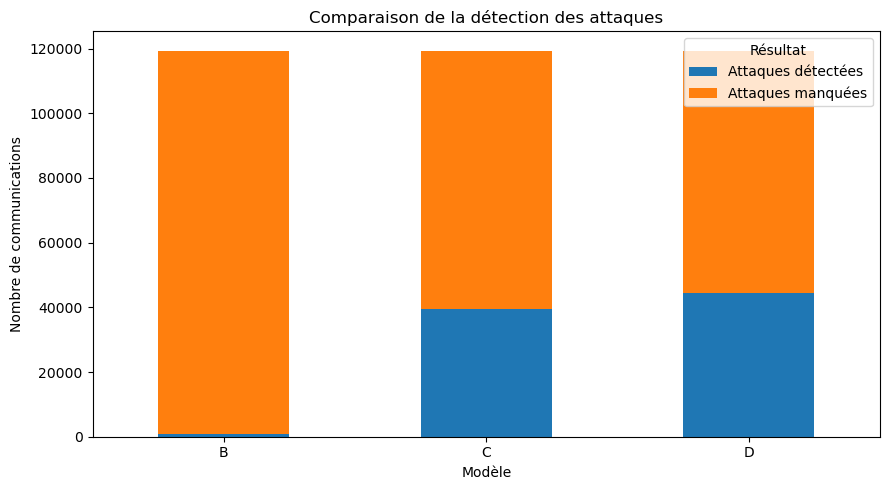

In [66]:
comparaison_attaques = synthese_finale.set_index("Modèle")[
    ["Attaques détectées", "Attaques manquées"]
]

ax = comparaison_attaques.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

ax.set_title("Comparaison de la détection des attaques")
ax.set_xlabel("Modèle")
ax.set_ylabel("Nombre de communications")
ax.tick_params(axis="x", rotation=0)

plt.legend(title="Résultat")
plt.tight_layout()
plt.show()

Construction du tableau des **attaques détectées** et **attaques manquées** pour B, C et D. Chaque barre empilée totalise le nombre d’attaques réelles du Test, la part détectée illustre le rappel.

---

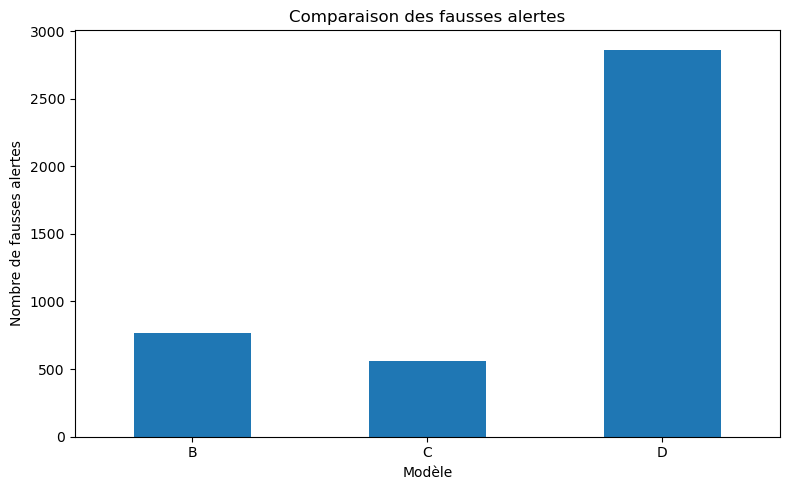

In [67]:
ax = synthese_finale.plot(
    x="Modèle",
    y="Fausses alertes",
    kind="bar",
    figsize=(8, 5),
    legend=False
)

ax.set_title("Comparaison des fausses alertes")
ax.set_xlabel("Modèle")
ax.set_ylabel("Nombre de fausses alertes")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

Préparation de la comparaison du nombre de **fausses alertes** par modèle. Cet indicateur correspond à des communications réellement normales mais signalées comme suspectes. Il ne faut pas le confondre avec le total des alertes.

---

In [68]:
from pathlib import Path

dossier_figures = Path("reports/figures")
dossier_figures.mkdir(parents=True, exist_ok=True)

# Graphique des attaques détectées et manquées
ax = comparaison_attaques.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

ax.set_title("Comparaison de la détection des attaques")
ax.set_xlabel("Modèle")
ax.set_ylabel("Nombre de communications")
ax.tick_params(axis="x", rotation=0)

plt.legend(title="Résultat")
plt.tight_layout()

plt.savefig(
    dossier_figures / "comparaison_detection_attaques.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# Graphique des fausses alertes
ax = synthese_finale.plot(
    x="Modèle",
    y="Fausses alertes",
    kind="bar",
    figsize=(8, 5),
    legend=False
)

ax.set_title("Comparaison des fausses alertes")
ax.set_xlabel("Modèle")
ax.set_ylabel("Nombre de fausses alertes")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.savefig(
    dossier_figures / "comparaison_fausses_alertes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Graphiques enregistrés dans :", dossier_figures.resolve())

for fichier in dossier_figures.glob("*.png"):
    print("-", fichier.name)

Graphiques enregistrés dans : figures/
- comparaison_detection_attaques.png
- comparaison_fausses_alertes.png


`Path("reports/figures")` crée le dossier de sortie si nécessaire. Les deux graphiques sont enregistrés en PNG à **300 dpi** avec `bbox_inches="tight"`, puis les figures Matplotlib sont fermées. Les fichiers sont prêts à être intégrés au rapport et aux diapositives.